In [1]:
%load_ext autoreload
%autoreload 2
%load_ext jupyter_black

import sys
from pathlib import Path

scripts_path = str(Path.cwd().parents[1]) + "/scripts/"
if scripts_path not in sys.path:
    sys.path.insert(0, scripts_path)

from Config import MPLSTYLE

import Syn_Spec_toolkit as SSt

import numpy as np
import matplotlib.pyplot as plt, matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import astropy.units as u
import astropy.constants as const
from astropy.config import generate_config

generate_config(pkgname="synphot")

from sedfitter.sed import SEDCube
from synphot.models import Empirical1D
from synphot import units, SourceSpectrum
from astroquery.svo_fps import SvoFps

import matplotlib.colors as mcolors
import matplotlib.cm as cm
from tqdm import tqdm

if MPLSTYLE.exists():
    plt.style.use(str(MPLSTYLE))

In [ ]:
bp = SSt


<Quantity [18342., 19132.] Angstrom>

### Testing our class + plotting

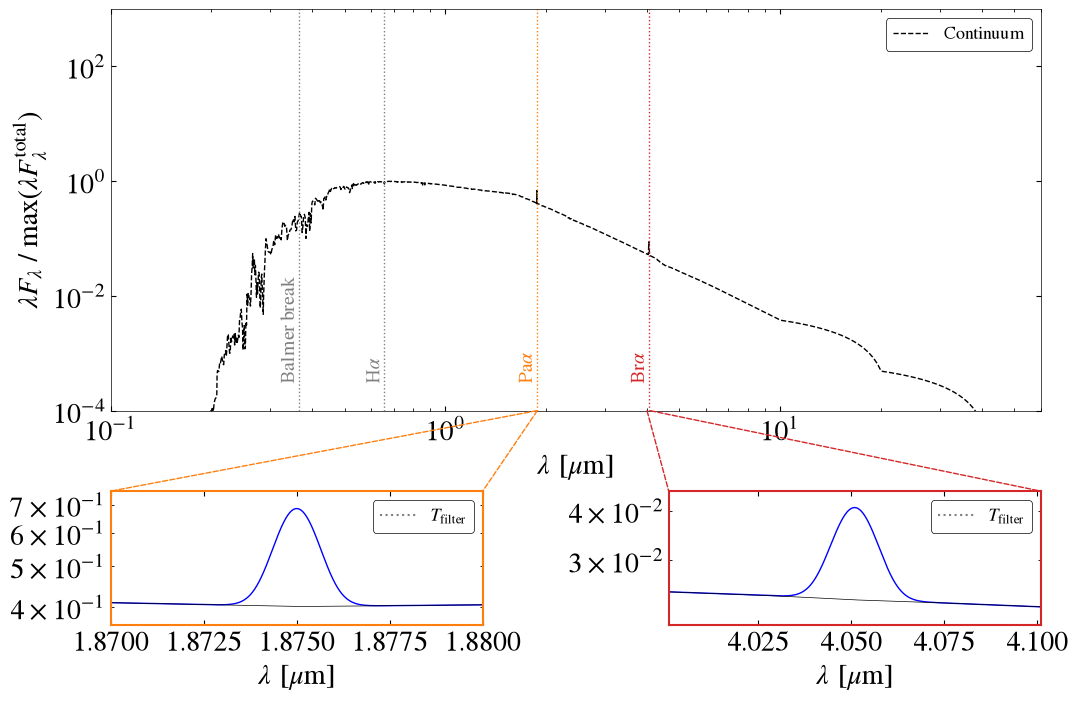

In [173]:
SPEC = SSt.Line_Strength(continuum_mode="Bessel", T_eff=5000, g_surface="g45")

Weq_pa = 10 * u.AA
Weq_br = 100 * u.AA

SPEC.Add_emission_line_to_spectrum(lam0=SSt.wave_pa_alpha.to(u.AA), Weq=Weq_pa)
SPEC.Add_emission_line_to_spectrum(lam0=SSt.wave_br_alpha.to(u.AA), Weq=Weq_br)

SPEC.Plot_spectrum_modeled_source(Weq1=Weq_pa, Weq2=Weq_br)

/home/slagter/Astronomy_master/STRW-MSC/SF_in_NGC/scripts/Syn_Spec_toolkit.py:22: UserWarning:  
 Parameter ranges include more than 1 model, showing first idx!!!
  from astroquery.svo_fps import SvoFps


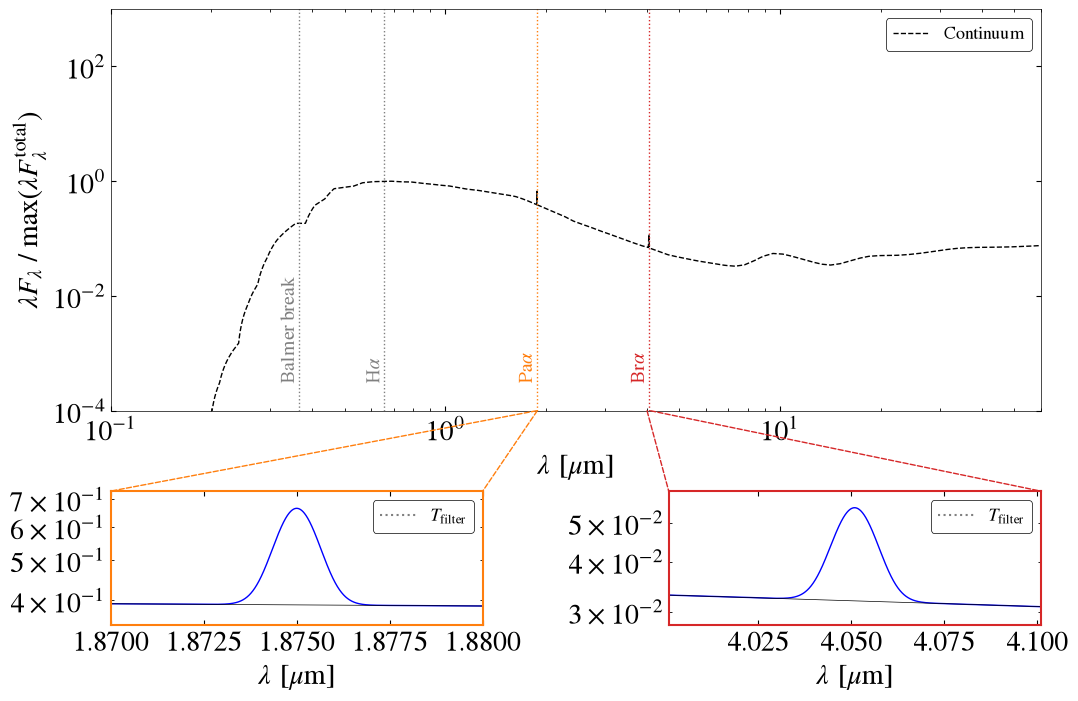

In [177]:
SPEC = SSt.Line_Strength(
    continuum_mode="Robitaille",
    parameter_range={
        "star.radius": (0.1, 10),
        "star.temperature": (4900, 5100),
        "disk.mass": None,
        "disk.rmax": None,
        "disk.beta": None,
        "disk.p": None,
        "disk.h100": None,
        "scattering": None,
        "inclination": (0.0, 10.0),  # Edge-on is 90 degrees
    },
)

Weq_pa = 10 * u.AA
Weq_br = 100 * u.AA

SPEC.Add_emission_line_to_spectrum(lam0=SSt.wave_pa_alpha.to(u.AA), Weq=Weq_pa)
SPEC.Add_emission_line_to_spectrum(lam0=SSt.wave_br_alpha.to(u.AA), Weq=Weq_br)

SPEC.Plot_spectrum_modeled_source(Weq1=Weq_pa, Weq2=Weq_br)

In [180]:
X = SPEC.Compute_model_abs_MAG(spectrum=SPEC.sp_tot, filter="F187N")
Y = SPEC.Compute_model_abs_MAG(spectrum=SPEC.sp_continuum, filter="F187N")

print(Y - X)

0.028794708985600437


### Checking $\Delta m $ as function of $W_{\mathrm{eq}}$ for a given continuum

In [184]:
filters_pa = ["F187N", "F115W", "F200W"]
filters_br = ["F405N", "F335M", "F356W", "F410M", "F444W", "F480M"]
N_Weq = 100

continuum_mode = "Bessel"
kwargs = {"T_eff": 6000, "g_surface": "g45"}

continuum_mode = "Robitaille"
kwargs = {
    "parameter_range": {
        "star.radius": (0.1, 10),
        "star.temperature": (4900, 5100),
        "disk.mass": None,
        "disk.rmax": None,
        "disk.beta": None,
        "disk.p": None,
        "disk.h100": None,
        "scattering": None,
        "inclination": (0.0, 10.0),  # Edge-on is 90 degrees
    }
}


Weqs, MAGS_per_filter_pa = SSt.Compute_delta_m_weq(
    lam0=SSt.wave_pa_alpha.to(u.AA),
    filters=filters_pa,
    N_Weq=N_Weq,
    continuum_mode=continuum_mode,
    **kwargs,
)

Weqs, MAGS_per_filter_br = SSt.Compute_delta_m_weq(
    lam0=SSt.wave_br_alpha.to(u.AA),
    filters=filters_br,
    N_Weq=N_Weq,
    continuum_mode=continuum_mode,
    **kwargs,
)

/home/slagter/Astronomy_master/STRW-MSC/SF_in_NGC/scripts/Syn_Spec_toolkit.py:22: UserWarning:  
 Parameter ranges include more than 1 model, showing first idx!!!
  from astroquery.svo_fps import SvoFps
Computing ∆m(W_eq): 100%|██████████| 100/100 [00:07<00:00, 12.77it/s]
/home/slagter/Astronomy_master/STRW-MSC/SF_in_NGC/scripts/Syn_Spec_toolkit.py:22: UserWarning:  
 Parameter ranges include more than 1 model, showing first idx!!!
  from astroquery.svo_fps import SvoFps
Computing ∆m(W_eq): 100%|██████████| 100/100 [00:17<00:00,  5.66it/s]


#### $Pa \alpha$ plots

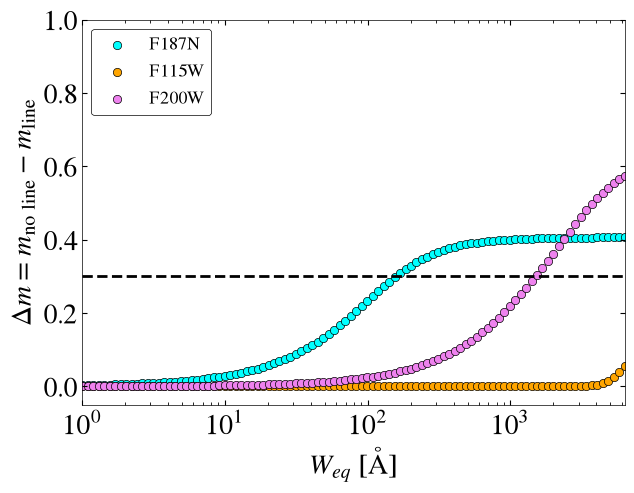

In [185]:
mag_diff_dic_pa = {}
colors = [
    "cyan",
    "orange",
    "violet",
]
for F_idx, FILT in enumerate(filters_pa):
    mag_diff_dic_pa[FILT] = (
        MAGS_per_filter_pa[F_idx, 0] - MAGS_per_filter_pa[F_idx, 1],
        colors[F_idx],
    )

SSt.Plot_delta_m_weq(
    Weqs,
    mag_diff_dic=mag_diff_dic_pa,
)

#### $Br \alpha$ plots

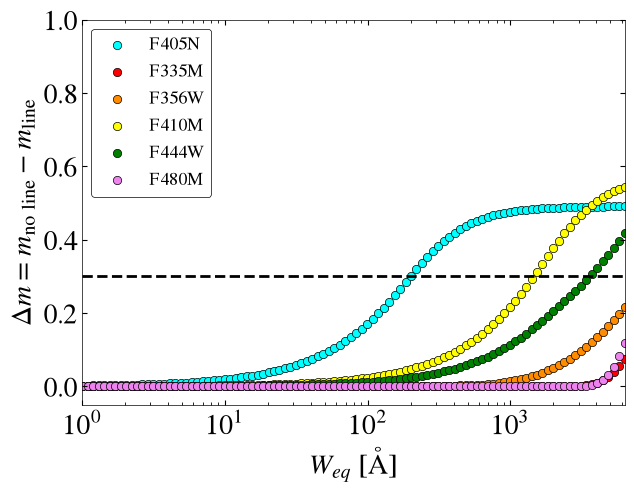

In [172]:
mag_diff_dic_br = {}
colors = [
    "cyan",
    "red",
    "darkorange",
    "yellow",
    "green",
    "violet",
]

for F_idx, FILT in enumerate(filters_br):
    mag_diff_dic_br[FILT] = (
        MAGS_per_filter_br[F_idx, 0] - MAGS_per_filter_br[F_idx, 1],
        colors[F_idx],
    )

SSt.Plot_delta_m_weq(
    Weqs,
    mag_diff_dic=mag_diff_dic_br,
)

#### Impact of the continuum filters